# Can Vision Transformers Predict Human Visual Attention?
## Basecamp exploration checkpoint

This notebook explores **CapMIT1003 mouse clicks** on MIT1003 images. Each row represents one recorded click during an image-description task. These figures describe clicking behaviour. An evaluation of human gaze would use MIT1003 eye-tracking maps and a separate ViT prediction experiment.

Data source: [CapMIT1003](https://github.com/mad-lab-fau/CapMIT1003). The team repository contains the original SQLite database and the images. Run the cells top to bottom to reproduce the figures and export `clean_clicks.csv`.

In [1]:
from contextlib import closing
from pathlib import Path
import sqlite3
from urllib.request import urlretrieve
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import gaussian_filter

project = Path("basecamp-team-26-main")
if not (project / "capmit1003.db").is_file() or not (project / "ALLSTIMULI").is_dir():
    archive = Path("basecamp-team-26-main.zip")
    if not archive.is_file():
        urlretrieve(
            "https://codeload.github.com/Zimeng0815/basecamp-team-26/zip/refs/heads/main",
            archive,
        )
    with ZipFile(archive) as repo_zip:
        repo_zip.extractall()

image_folder = project / "ALLSTIMULI"
db_path = project / "capmit1003.db"

query = '''
SELECT cl.click_id, cl.obs_uid, ca.usr_uid, im.img_uid, im.img_path,
       cl.x, cl.y, cl.click_time
FROM clicks AS cl
JOIN captions AS ca ON cl.obs_uid = ca.obs_uid
JOIN images AS im ON ca.img_uid = im.img_uid
ORDER BY cl.click_id
'''
with closing(sqlite3.connect(db_path.resolve().as_uri() + "?mode=ro", uri=True)) as conn:
    raw = pd.read_sql_query(query, conn, parse_dates=["click_time"])
    source_count = conn.execute("SELECT COUNT(*) FROM clicks").fetchone()[0]

unmatched_count = source_count - len(raw)
if unmatched_count < 0 or not raw["click_id"].is_unique:
    raise ValueError("The join produced duplicate click IDs.")
if raw.isna().any().any():
    raise ValueError("Review missing values before cleaning.")

raw["filename"] = raw["img_path"].map(lambda path: Path(path).name)
sizes = []
for filename in raw["filename"].unique():
    with Image.open(image_folder / filename) as image:
        sizes.append((filename, image.width, image.height))

dimensions = pd.DataFrame(sizes, columns=["filename", "width", "height"])
clicks = raw.merge(dimensions, on="filename", validate="many_to_one")
repeat_count = clicks.duplicated(subset=["obs_uid", "x", "y", "click_time"]).sum()
in_bounds = (
    (clicks["x"] >= 0) & (clicks["x"] < clicks["width"])
    & (clicks["y"] >= 0) & (clicks["y"] < clicks["height"])
)
excluded = clicks.loc[~in_bounds]
clean = clicks.loc[in_bounds].copy()
clean.to_csv("clean_clicks.csv", index=False)

print(f"Database click rows: {source_count:,}")
print(f"Rows without a complete observation-to-image match: {unmatched_count:,}")
print(f"Rows matched to images: {len(raw):,}")
print(f"Extra rows with the same observation, coordinates and timestamp: {repeat_count:,}")
print(f"Out-of-bounds rows: {len(excluded):,}")
print(f"Clean rows: {len(clean):,} across {clean['filename'].nunique():,} images")
print(excluded[["x", "y", "width", "height"]].to_string(index=False))

Database click rows: 27,865
Rows without a complete observation-to-image match: 2,501
Rows matched to images: 25,364
Extra rows with the same observation, coordinates and timestamp: 100
Out-of-bounds rows: 1
Clean rows: 25,363 across 1,002 images
 x   y  width  height
-2 390   1024     729


## 1. Click locations on the cat image

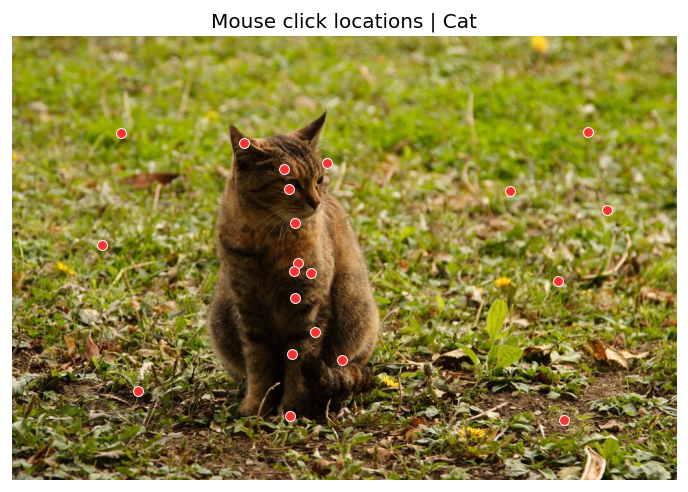

In [2]:
cat_name = "i2145018847.jpeg"
cat = clean.loc[clean["filename"] == cat_name]
with Image.open(image_folder / cat_name) as source:
    image = source.convert("RGB")

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.imshow(image)
ax.scatter(cat["x"], cat["y"], color="#f93233", edgecolors="white", linewidths=0.6, s=35)
ax.set_title("Mouse click locations | Cat")
ax.set_axis_off()
plt.show()

The cat image contains **21 valid mouse clicks** from **5 participants**, with points on both the cat and the grass.

## 2. Click density on the palm-tree image

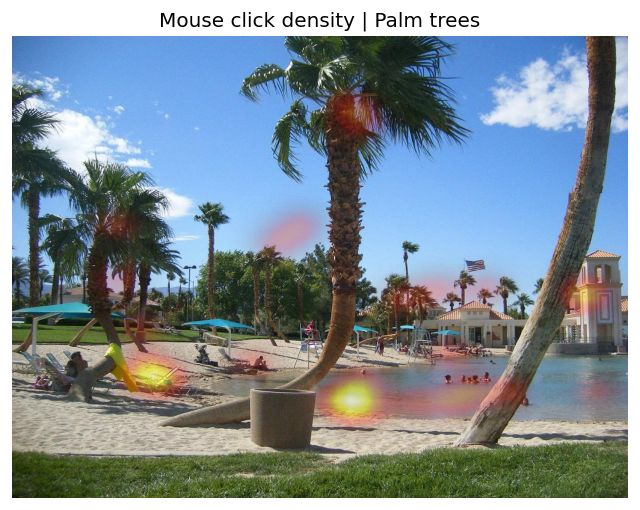

In [3]:
palm_name = "i1177391126.jpeg"
palm = clean.loc[clean["filename"] == palm_name]
with Image.open(image_folder / palm_name) as source:
    image = source.convert("RGB")

counts, _, _ = np.histogram2d(
    palm["y"], palm["x"], bins=50,
    range=[[0, image.height], [0, image.width]],
)
heat = gaussian_filter(counts, sigma=1.5)
extent = (0, image.width, image.height, 0)

fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(image, extent=extent)
ax.imshow(
    heat, extent=extent, origin="upper", cmap="hot",
    interpolation="bilinear", alpha=0.72 * heat / heat.max(),
)
ax.set_title("Mouse click density | Palm trees")
ax.set_axis_off()
plt.show()

Of the **26 valid clicks** from **4 participants**, the most concentrated areas are near the beach seating and the water's edge.

## 3. How far are clicks from the centre?
Distances are divided by half the image diagonal. Zero is the centre and one is a corner. For comparison, the uniform baseline samples the same number of positions within each image.

Mean observed distance: 0.4112
Mean uniform distance:  0.5381


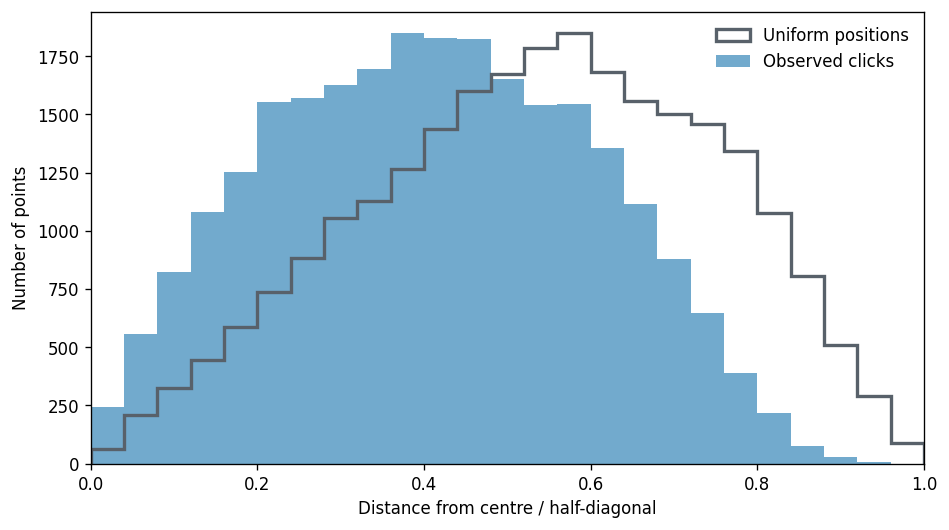

In [4]:
centre_x = clean["width"].to_numpy() / 2
centre_y = clean["height"].to_numpy() / 2
half_diagonal = np.hypot(centre_x, centre_y)
distances = np.hypot(clean["x"] - centre_x, clean["y"] - centre_y) / half_diagonal

rng = np.random.default_rng(42)
uniform = np.hypot(
    rng.uniform(-centre_x, centre_x),
    rng.uniform(-centre_y, centre_y),
) / half_diagonal

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(0, 1, 26)
ax.hist(uniform, bins=bins, histtype="step", linewidth=2, color="#58616a", label="Uniform positions")
ax.hist(distances, bins=bins, alpha=0.65, color="#277db2", label="Observed clicks")
ax.set(xlabel="Distance from centre / half-diagonal", ylabel="Number of points", xlim=(0, 1))
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print(f"Mean observed distance: {distances.mean():.4f}")
print(f"Mean uniform distance:  {uniform.mean():.4f}")

The mean distance was **41.1% of the half-diagonal** for observed clicks and **53.8%** for matched uniform positions. In this dataset, clicks were closer to the centre on average.

## Outlier check and decision log

In [5]:
q1, q3 = np.quantile(distances, [0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
flagged = ((distances < lower) | (distances > upper)).sum()
print(f"IQR fences: {lower:.3f}, {upper:.3f}")
print(f"Valid clicks outside the IQR fences: {flagged}")
print(f"Maximum observed normalized distance: {distances.max():.3f}")

IQR fences: -0.185, 1.003
Valid clicks outside the IQR fences: 0
Maximum observed normalized distance: 0.952


| Check | Decision |
|---|---|
| Observation-to-image match | Excluded **2,501** click rows that could not be linked to a caption and image; without that link, the image-relative location cannot be analysed. |
| Image bounds | Excluded **1** row. Its coordinates were **(-2, 390)** on a **1024 × 729** image. Kept the source database intact. |
| Missing data and types | Found no missing fields in the joined records. Parsed the click timestamp as a date-time. |
| Repeated records | **100** extra rows shared an observation, coordinates and a timestamp. Retained them because a timestamp recorded to the second does not distinguish all repeat clicks. The team's original cleaned export also retained these rows. |
| Distance outliers | The 1.5×IQR check flagged **0** in-bounds clicks. Retained valid edge clicks because participants could legitimately click near an image edge. |

The visualisations and summary statistics use the **25,363** in-bounds rows.